# LAMBADA Evaluation for DualStreamLLM
This notebook evaluates the DualStreamLLM using a separator model for deconvolution on the LAMBADA dataset.


In [5]:
import json
import torch
import random
import os 
import sys

import numpy as np
import matplotlib.pyplot as plt
import re
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch.nn.functional as F

# Add project root to path
sys.path.append(os.getcwd())

from generate_dual_stream import load_checkpoint, generate_dual_linear
from model import DualStreamLLM

In [2]:
def initialize_models(device, model_name, separator_model_name, checkpoint_path, use_pretrained):
    """Initialize tokenizer and models with given configuration."""

    # Load Tokenizer
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    # Load DualStream Model
    if use_pretrained:
        dual_model = load_checkpoint(checkpoint_path, model_name, device)
    else:
        dual_model = DualStreamLLM(
            model_name=model_name,
            freeze_backbone=True,
            optimize_memory=True,
            embedding_init_strategy='copy',
            objective='distillation',
            shared_embeddings=True
        ).to(device)
        dual_model.eval()
        print("Untrained DualStreamLLM created successfully")

    # Load Separator Model
    print(f"Loading separator model: {separator_model_name}")
    separator_model = AutoModelForCausalLM.from_pretrained(
        separator_model_name,
        torch_dtype=torch.bfloat16
    ).to(device)
    separator_model.eval()
    print("Models loaded successfully.")
    
    return tokenizer, dual_model, separator_model

In [ ]:
def run_lambada_evaluation(
    tokenizer=None,
    dual_model=None,
    separator_model=None,
    dataset_path=None,
    device=None,
    alpha=None,
    beta=None,
    temperature=None,
    num_examples_to_print=None,
    max_new_tokens=None,
    model_name=None,
    separator_model_name=None,
    use_pretrained=None,
    checkpoint_path=None
):
    """
    Execute full LAMBADA evaluation pipeline: inference and visualization.
    
    Args:
        tokenizer: Pre-loaded tokenizer
        dual_model: Pre-loaded DualStreamLLM model object
        separator_model: Pre-loaded separator model object
        dataset_path: Path to the dataset
        device: Device to use for computation
        alpha: Alpha parameter for generation
        beta: Beta parameter for generation
        temperature: Temperature parameter for generation
        num_examples_to_print: Number of examples to print
        max_new_tokens: Maximum number of tokens to generate
        model_name: Name of the main model (for logging/visualization)
        separator_model_name: Name of the separator model (for logging/visualization)
        use_pretrained: Whether pretrained model was used (for logging/visualization)
        checkpoint_path: Path to checkpoint file (for logging/visualization)
    
    Returns:
        Dict with evaluation results and statistics.
    """    
    print(f"Starting LAMBADA evaluation with configuration:")
    print(f"  Model: {model_name}")
    print(f"  Separator: {separator_model_name}")
    print(f"  Device: {device}")
    print(f"  Alpha: {alpha}, Beta: {beta}, Temperature: {temperature}")
    print(f"  Max tokens: {max_new_tokens}\n")
    
    # Load and sort dataset
    with open(dataset_path, 'r') as f:
        data = [json.loads(line) for line in f]
    
    print("Sorting dataset by length to optimize pairing...")
    data_sorted = sorted(data, key=lambda x: len(tokenizer.encode(x['prompt'])))
    
    # Pair examples with similar lengths
    pairs = []
    for i in range(0, len(data_sorted) - 1, 2):
        pairs.append((data_sorted[i], data_sorted[i+1]))
    
    # Shuffle pairs
    random.seed(42)
    random.shuffle(pairs)
    
    correct_a = 0
    correct_b = 0
    total = 0
    printed_count = 0
    results_a = []
    results_b = []
    
    pbar = tqdm(pairs, desc="Evaluating LAMBADA")
    
    for item_a, item_b in pbar:
        # Tokenize prompts
        prompt_tokens_a = tokenizer(item_a['prompt'], return_tensors='pt')['input_ids'].to(device)
        prompt_tokens_b = tokenizer(item_b['prompt'], return_tensors='pt')['input_ids'].to(device)
        
        # Left-truncate to match lengths
        len_a = prompt_tokens_a.shape[1]
        len_b = prompt_tokens_b.shape[1]
        min_len = min(len_a, len_b)
        
        input_tokens_a = prompt_tokens_a[:, -min_len:]
        input_tokens_b = prompt_tokens_b[:, -min_len:]
        
        # Dual-Stream Inference
        with torch.no_grad():
            out_a, out_b = generate_dual_linear(
                dual_model,
                separator_model,
                input_tokens_a,
                input_tokens_b,
                tokenizer,
                max_new_tokens=max_new_tokens,
                temperature=temperature,
                alpha=alpha,
                beta=beta
            )
        
        # Check correctness
        full_correct_text_a = item_a['prompt'] + " " + item_a['completion']
        full_correct_text_b = item_b['prompt'] + " " + item_b['completion']
        
        generated_text_a = tokenizer.decode(out_a[0, :min_len + 1], skip_special_tokens=True)
        generated_text_b = tokenizer.decode(out_b[0, :min_len + 1], skip_special_tokens=True)
        
        is_correct_a = full_correct_text_a.startswith(generated_text_a)
        is_correct_b = full_correct_text_b.startswith(generated_text_b)
        
        correct_a += int(is_correct_a)
        correct_b += int(is_correct_b)
        total += 1
        
        results_a.append(is_correct_a)
        results_b.append(is_correct_b)
        
        # Print examples
        if printed_count < num_examples_to_print:
            print(f"\n--- Example Pair {printed_count + 1} [Length: {min_len} tokens] ---")
            print(f"Stream A Prompt: {item_a['prompt']}")
            print(f"Stream A Target Completion: '{item_a['completion']}'")
            
            first_gen_token_id_a = out_a[0, min_len].item()
            first_gen_token_a = tokenizer.convert_ids_to_tokens(first_gen_token_id_a)
            print(f"Stream A First Generated Token: '{first_gen_token_a}' (ID: {first_gen_token_id_a})")
            
            if max_new_tokens > 1:
                full_gen_a = tokenizer.decode(out_a[0, min_len:], skip_special_tokens=True)
                print(f"Stream A Full Generation: '{full_gen_a}'")
            
            print(f"Stream A Result: {'✓ CORRECT' if is_correct_a else '✗ WRONG'}")
            print("-" * 15)
            
            print(f"Stream B Prompt: {item_b['prompt']}")
            print(f"Stream B Target Completion: '{item_b['completion']}'")
            
            first_gen_token_id_b = out_b[0, min_len].item()
            first_gen_token_b = tokenizer.convert_ids_to_tokens(first_gen_token_id_b)
            print(f"Stream B First Generated Token: '{first_gen_token_b}' (ID: {first_gen_token_id_b})")
            
            if max_new_tokens > 1:
                full_gen_b = tokenizer.decode(out_b[0, min_len:], skip_special_tokens=True)
                print(f"Stream B Full Generation: '{full_gen_b}'")
            
            print(f"Stream B Result: {'✓ CORRECT' if is_correct_b else '✗ WRONG'}")
            printed_count += 1
            print()
            print('=' * 70)
        
        pbar.set_postfix({
            "Acc A": f"{correct_a/total:.4f}", 
            "Acc B": f"{correct_b/total:.4f}",
            "Acc Total": f"{(correct_a+correct_b)/(2*total):.4f}"
        })
    
    # Print results summary
    print(f"\nFinal Evaluation Results:")
    print(f"Total pairs processed: {total}")
    print(f"Accuracy Stream A: {correct_a/total:.4f}")
    print(f"Accuracy Stream B: {correct_b/total:.4f}")
    print(f"Total Accuracy: {(correct_a + correct_b)/(2 * total):.4f}")
    
    # Bootstrap analysis
    print("\nPerforming bootstrap analysis...")
    n_bootstrap = 1000
    np.random.seed(42)
    
    bootstrap_acc_a = []
    bootstrap_acc_b = []
    bootstrap_acc_total = []
    
    for _ in range(n_bootstrap):
        indices = np.random.choice(len(results_a), size=len(results_a), replace=True)
        acc_a = np.mean([results_a[i] for i in indices])
        acc_b = np.mean([results_b[i] for i in indices])
        acc_total = (acc_a + acc_b) / 2
        
        bootstrap_acc_a.append(acc_a)
        bootstrap_acc_b.append(acc_b)
        bootstrap_acc_total.append(acc_total)
    
    # Calculate confidence intervals
    ci_95_a = np.percentile(bootstrap_acc_a, [2.5, 97.5])
    ci_95_b = np.percentile(bootstrap_acc_b, [2.5, 97.5])
    ci_95_total = np.percentile(bootstrap_acc_total, [2.5, 97.5])
    
    # Create visualization
    print("Creating visualization...")
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    
    # Prepare config string for title
    config_str = f"Model: {model_name.split('/')[-1]} | "
    config_str += f"Separator: {separator_model_name.split('/')[-1]}\n"
    
    run_match = re.search(r'run_[^/]+', checkpoint_path)
    step_match = re.search(r'checkpoint-(\d+)', checkpoint_path)
    
    run_name = run_match.group() if run_match else "unknown"
    step = step_match.group(1) if step_match else "unknown"
    
    config_str += f"Pretrained (not finetuned) | " if use_pretrained else f"Finetuned ({run_name} step {step}) | "
    config_str += f"α={alpha}, β={beta} | "
    config_str += f"T={temperature}"
    
    # Stream A histogram
    axes[0].hist(bootstrap_acc_a, bins=30, color='#2ecc71', alpha=0.7, edgecolor='black')
    axes[0].axvline(correct_a/total, color='red', linestyle='--', linewidth=2, label=f'Observed: {correct_a/total:.4f}')
    axes[0].axvline(ci_95_a[0], color='orange', linestyle=':', linewidth=2, label=f'95% CI: [{ci_95_a[0]:.4f}, {ci_95_a[1]:.4f}]')
    axes[0].axvline(ci_95_a[1], color='orange', linestyle=':', linewidth=2)
    axes[0].set_xlabel('Accuracy', fontsize=11, fontweight='bold')
    axes[0].set_ylabel('Frequency', fontsize=11, fontweight='bold')
    axes[0].set_title('Stream A - Bootstrap Distribution', fontsize=12, fontweight='bold')
    axes[0].legend(fontsize=10)
    axes[0].grid(alpha=0.3, linestyle='--')
    
    # Stream B histogram
    axes[1].hist(bootstrap_acc_b, bins=30, color='#3498db', alpha=0.7, edgecolor='black')
    axes[1].axvline(correct_b/total, color='red', linestyle='--', linewidth=2, label=f'Observed: {correct_b/total:.4f}')
    axes[1].axvline(ci_95_b[0], color='orange', linestyle=':', linewidth=2, label=f'95% CI: [{ci_95_b[0]:.4f}, {ci_95_b[1]:.4f}]')
    axes[1].axvline(ci_95_b[1], color='orange', linestyle=':', linewidth=2)
    axes[1].set_xlabel('Accuracy', fontsize=11, fontweight='bold')
    axes[1].set_ylabel('Frequency', fontsize=11, fontweight='bold')
    axes[1].set_title('Stream B - Bootstrap Distribution', fontsize=12, fontweight='bold')
    axes[1].legend(fontsize=10)
    axes[1].grid(alpha=0.3, linestyle='--')
    
    # Total histogram
    axes[2].hist(bootstrap_acc_total, bins=30, color='#9b59b6', alpha=0.7, edgecolor='black')
    axes[2].axvline((correct_a+correct_b)/(2*total), color='red', linestyle='--', linewidth=2, label=f'Observed: {(correct_a+correct_b)/(2*total):.4f}')
    axes[2].axvline(ci_95_total[0], color='orange', linestyle=':', linewidth=2, label=f'95% CI: [{ci_95_total[0]:.4f}, {ci_95_total[1]:.4f}]')
    axes[2].axvline(ci_95_total[1], color='orange', linestyle=':', linewidth=2)
    axes[2].set_xlabel('Accuracy', fontsize=11, fontweight='bold')
    axes[2].set_ylabel('Frequency', fontsize=11, fontweight='bold')
    axes[2].set_title('Overall - Bootstrap Distribution', fontsize=12, fontweight='bold')
    axes[2].legend(fontsize=10)
    axes[2].grid(alpha=0.3, linestyle='--')
    
    overall_title = f"LAMBADA Bootstrap Accuracy Distribution ({n_bootstrap} iterations)\n{config_str}"
    fig.suptitle(overall_title, fontsize=14, fontweight='bold', y=0.99)
    
    plt.tight_layout()
    plt.subplots_adjust(top=0.75)
    plt.savefig('lambada_evaluation_results.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f"\nBootstrap Results (95% Confidence Intervals):")
    print(f"Stream A: {correct_a/total:.4f} [{ci_95_a[0]:.4f}, {ci_95_a[1]:.4f}]")
    print(f"Stream B: {correct_b/total:.4f} [{ci_95_b[0]:.4f}, {ci_95_b[1]:.4f}]")
    print(f"Overall:  {(correct_a+correct_b)/(2*total):.4f} [{ci_95_total[0]:.4f}, {ci_95_total[1]:.4f}]")
    print(f"\nHistogram saved as 'lambada_evaluation_results.png'")
    
    # Return results dictionary
    return {
        'correct_a': correct_a,
        'correct_b': correct_b,
        'total': total,
        'acc_a': correct_a / total,
        'acc_b': correct_b / total,
        'acc_total': (correct_a + correct_b) / (2 * total),
        'ci_95_a': ci_95_a,
        'ci_95_b': ci_95_b,
        'ci_95_total': ci_95_total,
    }


Starting LAMBADA evaluation with configuration:
  Model: Qwen/Qwen2.5-3B
  Separator: Qwen/Qwen2.5-0.5B
  Device: cuda:0
  Alpha: 0.1, Beta: 0.1, Temperature: 0.0001
  Max tokens: 1



Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Untrained DualStreamLLM created successfully
Loading separator model: Qwen/Qwen2.5-0.5B


`torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Models loaded successfully.
Sorting dataset by length to optimize pairing...


Evaluating LAMBADA:   0%|          | 0/2155 [00:00<?, ?it/s]


--- Example Pair 1 [Length: 92 tokens] ---
Stream A Prompt: not only did he not fully trust the constable , but he also doubted the little man 's abilities to comprehend it . `` we shall see what turns up . '' `` where are you going , inspector ? '' he was turning off the path , towards a certain manor . `` i have an important question to ask the good marquis . '' ~ ~ ~ the sky was beginning to darken when he was ushered into the sitting room to wait for the
Stream A Target Completion: 'marquis'
Stream A First Generated Token: 'Ġ.' (ID: 659)
Stream A Result: ✗ WRONG
---------------
Stream B Prompt: well , he 's actually not my uncle , he 's my godfather but i could n't say godfather when i was little so he told me to call him uncle . he told me i looked like my grandmother , '' said vanessa . `` do you think we could be some kin to one another ? '' i asked . `` it 's the only logical explanation for us resembling each other to the point of almost looking like twins , '' said
Stream B 

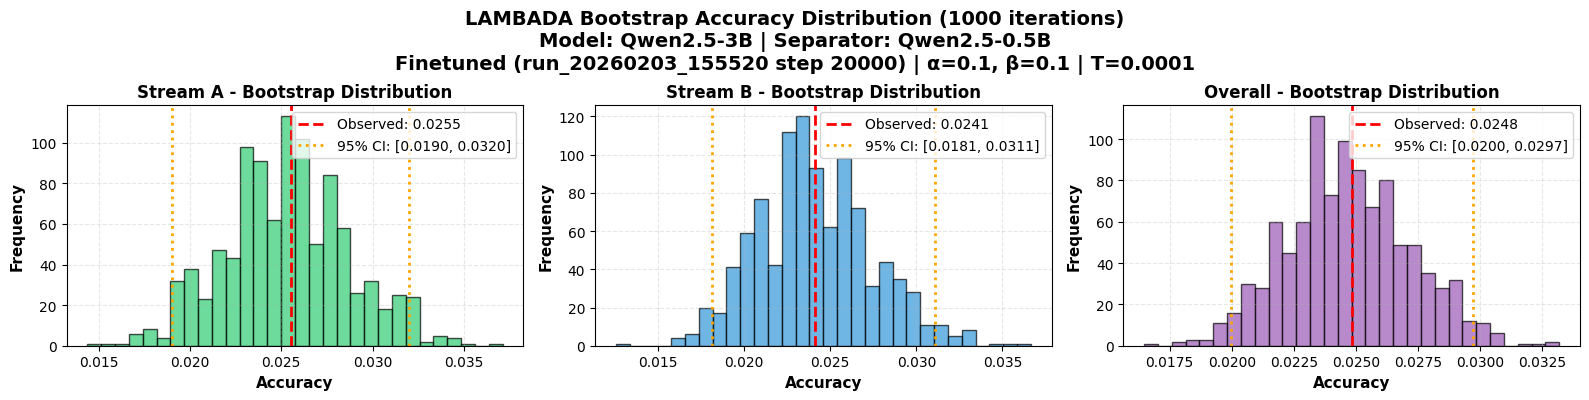


Bootstrap Results (95% Confidence Intervals):
Stream A: 0.0255 [0.0190, 0.0320]
Stream B: 0.0241 [0.0181, 0.0311]
Overall:  0.0248 [0.0200, 0.0297]

Histogram saved as 'lambada_evaluation_results.png'


{'correct_a': 55,
 'correct_b': 52,
 'total': 2155,
 'acc_a': 0.025522041763341066,
 'acc_b': 0.024129930394431554,
 'acc_total': 0.024825986078886312,
 'ci_95_a': array([0.01902552, 0.03201856]),
 'ci_95_b': array([0.01809745, 0.03109049]),
 'ci_95_total': array([0.0199536 , 0.02969838])}

In [ ]:
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
model_name = 'Qwen/Qwen2.5-3B'
separator_model_name = 'Qwen/Qwen2.5-0.5B'
checkpoint_path = 'checkpoints/run_20260203_155520/checkpoint-20000/model.pt'
use_pretrained = False

# Load models once
tokenizer, dual_model, separator_model = initialize_models(
    device=device,
    model_name=model_name,
    separator_model_name=separator_model_name,
    checkpoint_path=checkpoint_path,
    use_pretrained=use_pretrained
)

# Run evaluation with pre-loaded models
run_lambada_evaluation(
    tokenizer=tokenizer,
    dual_model=dual_model,
    separator_model=separator_model,
    dataset_path='lambada_test_filtered.jsonl',
    device=device,
    alpha=0.1,
    beta=0.1,
    temperature=0.0001,
    num_examples_to_print=10,
    max_new_tokens=1,  # Set to 1 for standard LAMBADA accuracy, or more for generation
    model_name=model_name,
    separator_model_name=separator_model_name,
    use_pretrained=use_pretrained,
    checkpoint_path=checkpoint_path
);

In [ ]:
# 